# Step 2 (partie 1) : Rééchantillonnage du dataset supervisé

**Objectif du TP** : tester une méthode de *under-sampling*, une méthode d'*over-sampling* et une *combinaison des deux*, puis comparer leur effet sur la qualité des résultats (toutes les métriques) avec **kNN, SVM et Random Forest**.

## Plan

| Jeu | Méthode | Effectif par classe |
|---|---|---|
| 1. Under-sampling | `RandomUnderSampler` | effectif de la classe minoritaire (Froid) pour chaque classe |
| 2. Over-sampling | `SMOTE` | effectif de la classe majoritaire (Tempéré) pour chaque classe |
| 3. Combinaison | `SMOTE` (Froid seulement) puis le **même** `RandomUnderSampler` (Tempéré et Chaud) | `COMBO_N` (≈ 160 000) pour chaque classe |

## Règles respectées
- On part du **train et du test** déjà produits par le notebook de prétraitement (split chronologique conservé).
- Le rééchantillonnage ne touche **que le train**. Le **test reste intact** (distribution d'origine), sinon les métriques ne seraient pas comparables.
- Mêmes hyperparamètres pour tous les jeux : on compare des méthodes de rééchantillonnage, pas des réglages.
- Chaque jeu est sauvegardé dans **son propre dossier**.

## Méthodes ajoutées (les 3 jeux ci-dessus sont conservés tels quels)

| Jeu | Famille | Méthode | Principe |
|---|---|---|---|
| 4 | Under-sampling | `NearMiss` (version 1) | garde les points majoritaires les plus proches des minoritaires |
| 5 | Under-sampling | `TomekLinks` | supprime les points majoritaires formant un lien de Tomek (nettoyage de frontière) |
| 6 | Under-sampling | `EditedNearestNeighbours` (ENN) | supprime les points mal classés par leurs 3 plus proches voisins |
| 7 | Over-sampling | `RandomOverSampler` | duplique des points minoritaires au hasard |
| 8 | Over-sampling | `ADASYN` | comme SMOTE, mais plus de points synthétiques dans les zones difficiles |
| 9 | Over-sampling | `BorderlineSMOTE` | SMOTE uniquement à partir des points proches de la frontière |
| 10 | Combinaison | `SMOTE` + `TomekLinks` | sur-échantillonnage puis nettoyage des liens de Tomek |
| 11 | Combinaison | `SMOTE` + `ENN` | sur-échantillonnage puis nettoyage par ENN |

Les jeux 4 à 11 sont aussi entraînés avec kNN, SVM et Random Forest (mêmes hyperparamètres), évalués sur le même test, puis comparés aux jeux 1 à 3 pour choisir la meilleure méthode.


## 0. Installation, imports et configuration

In [1]:
!pip install -q imbalanced-learn

In [ ]:
import os, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from imblearn.over_sampling import SMOTE, RandomOverSampler, ADASYN, BorderlineSMOTE
from imblearn.under_sampling import RandomUnderSampler, NearMiss, TomekLinks, EditedNearestNeighbours

from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_recall_fscore_support, matthews_corrcoef, confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

try:  # Colab : montage de Drive ; ailleurs on ignore
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

# ---------------- Configuration ----------------
BASE    = os.environ.get("DM_BASE", "/content/drive/MyDrive/data mining")
IN_DIR  = f"{BASE}/supervised_dataset"      # sortie du notebook de prétraitement
OUT_DIR = f"{BASE}/resampling"              # un sous-dossier par méthode sera créé ici
os.makedirs(OUT_DIR, exist_ok=True)

SEED    = 42
COMBO_N = int(os.environ.get("DM_COMBO_N", 160_000))   # effectif par classe du jeu 3
SVM_MAX = int(os.environ.get("DM_SVM_MAX", 50_000))    # taille max du train du SVM (voir section 5)
FIX_SYNTHETIC = True   # SMOTE : arrondir month/year et recalculer sin/cos des points synthétiques

FOLDERS = {
    "1_undersampling_RUS":     "1. Under-sampling (RUS)",
    "2_oversampling_SMOTE":    "2. Over-sampling (SMOTE)",
    "3_combinaison_SMOTE_RUS": "3. Combinaison (SMOTE + RUS)",
    # ---- méthodes ajoutées ----
    "4_undersampling_NearMiss":      "4. Under-sampling (NearMiss)",
    "5_undersampling_Tomek":         "5. Under-sampling (Tomek Links)",
    "6_undersampling_ENN":           "6. Under-sampling (ENN)",
    "7_oversampling_ROS":            "7. Over-sampling (RandomOver)",
    "8_oversampling_ADASYN":         "8. Over-sampling (ADASYN)",
    "9_oversampling_BorderlineSMOTE":"9. Over-sampling (Borderline-SMOTE)",
    "10_combinaison_SMOTE_Tomek":    "10. Combinaison (SMOTE + Tomek)",
    "11_combinaison_SMOTE_ENN":      "11. Combinaison (SMOTE + ENN)",
}
COLORS = ["#4c72b0", "#dd8452", "#c44e52"]

## 1. Chargement du dataset supervisé et distribution initiale

In [3]:
tr  = pd.read_parquet(f"{IN_DIR}/supervised_train.parquet")
te  = pd.read_parquet(f"{IN_DIR}/supervised_test.parquet")
cfg = json.load(open(f"{IN_DIR}/preprocessing_config.json", encoding="utf-8"))
scaler = joblib.load(f"{IN_DIR}/robust_scaler.joblib")

FEATURES, SCALE_COLS, CLASS_NAMES = cfg["features"], cfg["scaled_features"], cfg["class_names"]

X_train, y_train = tr[FEATURES].reset_index(drop=True), tr["y"].astype(int).reset_index(drop=True)
X_test,  y_test  = te[FEATURES].reset_index(drop=True), te["y"].astype(int).reset_index(drop=True)

print("Features (%d) :" % len(FEATURES), FEATURES)
print("X_train :", X_train.shape, "| X_test :", X_test.shape)
assert X_train.notna().all().all() and X_test.notna().all().all()

Features (12) : ['d2m', 'slhf', 'ssr', 'str', 'u10', 'v10', 'sp', 'tp', 'month', 'year', 'month_sin', 'month_cos']
X_train : (607600, 12) | X_test : (151900, 12)


Distribution initiale (train)


,effectif,%
Froid,97397,16.03
Tempéré,272556,44.86
Chaud,237647,39.11


Distribution initiale (test)


,effectif,%
Froid,20169,13.28
Tempéré,59113,38.92
Chaud,72618,47.81


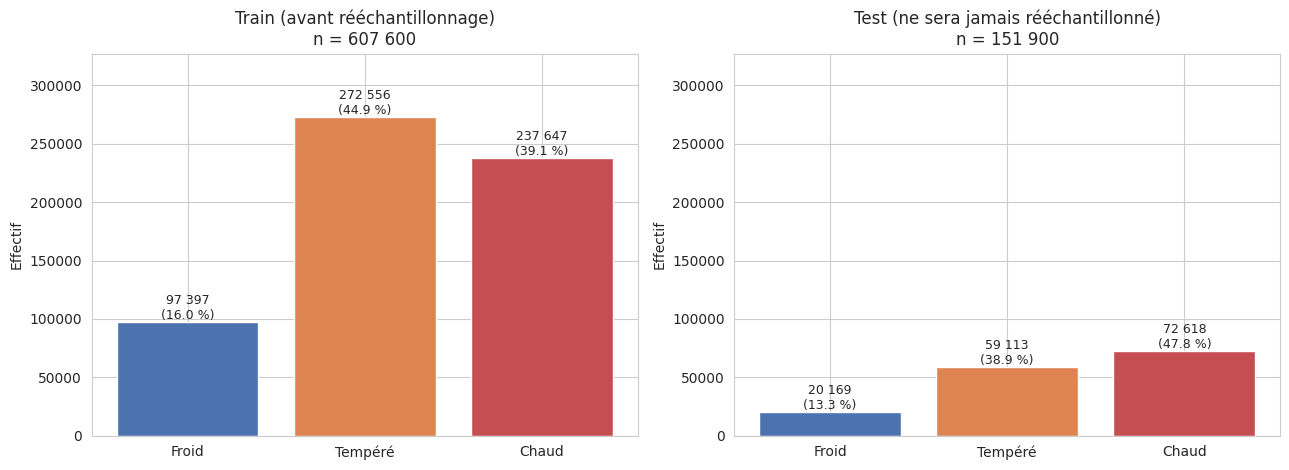

Rapport de déséquilibre (max/min) : 2.80


In [4]:
def counts(y):
    c = pd.Series(np.asarray(y)).value_counts().reindex(range(3)).fillna(0).astype(int)
    c.index = CLASS_NAMES
    return c

def dist_table(y):
    c = counts(y)
    return pd.DataFrame({"effectif": c, "%": (100 * c / c.sum()).round(2)})

def fmt(n):
    return f"{n:,}".replace(",", " ")

def plot_pair(y_left, y_right, t_left, t_right, path=None):
    # Deux diagrammes en barres côte à côte (effectifs + pourcentages), même échelle verticale.
    cl, cr = counts(y_left), counts(y_right)
    ymax = max(cl.max(), cr.max()) * 1.2
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
    for ax, c, t in [(axes[0], cl, t_left), (axes[1], cr, t_right)]:
        bars = ax.bar(CLASS_NAMES, c.values, color=COLORS, edgecolor="white")
        for b, v in zip(bars, c.values):
            ax.text(b.get_x() + b.get_width() / 2, v, f"{fmt(v)}\n({100 * v / c.sum():.1f} %)",
                    ha="center", va="bottom", fontsize=9)
        ax.set_ylim(0, ymax)
        ax.set_title(f"{t}\nn = {fmt(int(c.sum()))}")
        ax.set_ylabel("Effectif")
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=130, bbox_inches="tight")
    plt.show()

print("Distribution initiale (train)"); display(dist_table(y_train))
print("Distribution initiale (test)");  display(dist_table(y_test))
plot_pair(y_train, y_test, "Train (avant rééchantillonnage)", "Test (ne sera jamais rééchantillonné)")

n_froid, n_tempere, n_chaud = [int(v) for v in counts(y_train).values]
print(f"Rapport de déséquilibre (max/min) : {max(n_froid, n_tempere, n_chaud) / min(n_froid, n_tempere, n_chaud):.2f}")

## 2. Fonctions utilitaires (sauvegarde et correction des points synthétiques)

**Pourquoi corriger les points synthétiques ?** SMOTE interpole linéairement entre voisins. Sur nos features, cela produit des `month` et `year` non entiers, et des couples `month_sin` / `month_cos` incohérents avec `month`. Pour les points créés, on remet donc `month` et `year` à l'entier le plus proche (dans l'espace d'origine, via le `RobustScaler` sauvegardé), puis on recalcule `month_sin` et `month_cos`. Cette correction est désactivable avec `FIX_SYNTHETIC = False`.

In [5]:
def fix_synthetic(X):
    # Remet month/year à des entiers et recalcule sin/cos, dans l'espace d'origine du scaler.
    if not FIX_SYNTHETIC:
        return X
    X = X.copy()
    raw = pd.DataFrame(scaler.inverse_transform(X[SCALE_COLS]), columns=SCALE_COLS, index=X.index)
    raw["month"] = raw["month"].round().clip(1, 12)
    raw["year"]  = raw["year"].round()
    X[SCALE_COLS] = scaler.transform(raw[SCALE_COLS])
    X["month_sin"] = np.sin(2 * np.pi * raw["month"] / 12)
    X["month_cos"] = np.cos(2 * np.pi * raw["month"] / 12)
    return X

def folder(key):
    d = f"{OUT_DIR}/{key}"
    os.makedirs(d, exist_ok=True)
    return d

def save_set(key, X, y, y_before, note):
    d = folder(key)
    out = X.copy(); out["y"] = np.asarray(y)
    out.to_parquet(f"{d}/train_{key}.parquet", index=False)
    pd.concat({"avant": dist_table(y_before), "après": dist_table(y)}, axis=1).to_csv(f"{d}/distribution.csv")
    with open(f"{d}/README.txt", "w", encoding="utf-8") as f:
        f.write(note + "\n\nLe test n'est pas rééchantillonné : utiliser supervised_test.parquet du dossier supervised_dataset.\n")
    return d

## 3. Application des trois méthodes

Le train d'origine reste dans `X_train` / `y_train` et n'est jamais modifié : chaque méthode part de lui.

### 3.1 Jeu 1 : Under-sampling (`RandomUnderSampler`)
Chaque classe est réduite à l'effectif de la classe minoritaire (Froid) par tirage aléatoire sans remise.

Under-sampling : 607 600 -> 292 191 lignes (0.4 s)


avant           après       
        effectif      % effectif      %
Froid      97397  16.03    97397  33.33
Tempéré   272556  44.86    97397  33.33
Chaud     237647  39.11    97397  33.33

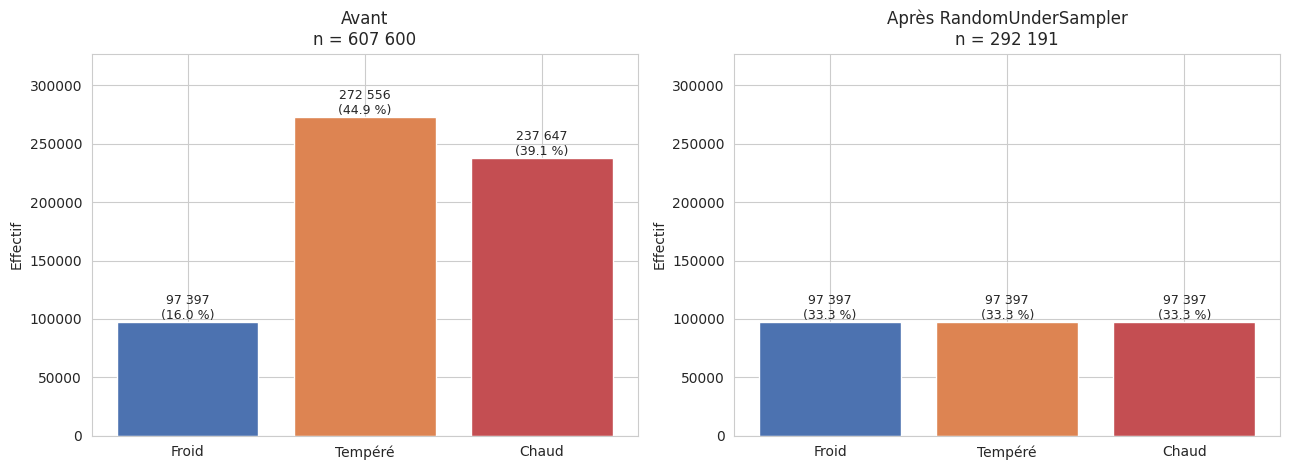

'/content/drive/MyDrive/data mining/resampling/1_undersampling_RUS'

In [6]:
t0 = time.time()
rus = RandomUnderSampler(sampling_strategy="auto", random_state=SEED)
X_u, y_u = rus.fit_resample(X_train, y_train)
X_u, y_u = X_u.reset_index(drop=True), pd.Series(np.asarray(y_u))
print(f"Under-sampling : {fmt(len(X_train))} -> {fmt(len(X_u))} lignes ({time.time() - t0:.1f} s)")

display(pd.concat({"avant": dist_table(y_train), "après": dist_table(y_u)}, axis=1))
d = folder("1_undersampling_RUS")
plot_pair(y_train, y_u, "Avant", "Après RandomUnderSampler", path=f"{d}/distribution_avant_apres.png")
save_set("1_undersampling_RUS", X_u, y_u, y_train, "RandomUnderSampler (sampling_strategy='auto', random_state=%d)" % SEED)

### 3.2 Jeu 2 : Over-sampling (`SMOTE`)
Les classes Froid et Chaud sont complétées par des points synthétiques jusqu'à l'effectif de la classe majoritaire (Tempéré).

Over-sampling : 607 600 -> 817 668 lignes (22.9 s)


avant           après       
        effectif      % effectif      %
Froid      97397  16.03   272556  33.33
Tempéré   272556  44.86   272556  33.33
Chaud     237647  39.11   272556  33.33

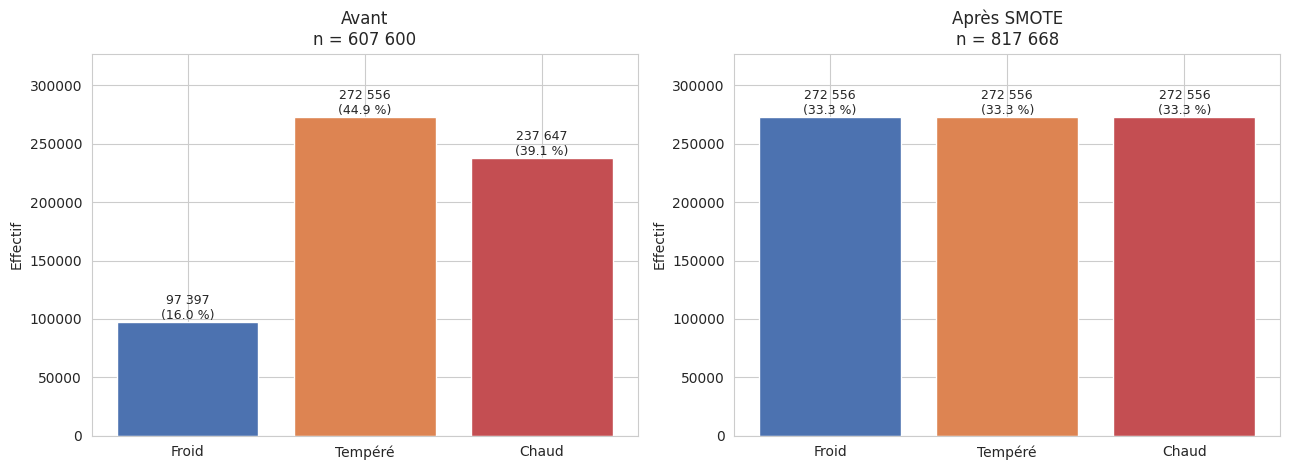

'/content/drive/MyDrive/data mining/resampling/2_oversampling_SMOTE'

In [7]:
t0 = time.time()
smote = SMOTE(sampling_strategy="auto", k_neighbors=5, random_state=SEED)
X_o, y_o = smote.fit_resample(X_train, y_train)
X_o, y_o = fix_synthetic(X_o.reset_index(drop=True)), pd.Series(np.asarray(y_o))
print(f"Over-sampling : {fmt(len(X_train))} -> {fmt(len(X_o))} lignes ({time.time() - t0:.1f} s)")

display(pd.concat({"avant": dist_table(y_train), "après": dist_table(y_o)}, axis=1))
d = folder("2_oversampling_SMOTE")
plot_pair(y_train, y_o, "Avant", "Après SMOTE", path=f"{d}/distribution_avant_apres.png")
save_set("2_oversampling_SMOTE", X_o, y_o, y_train, "SMOTE (sampling_strategy='auto', k_neighbors=5, random_state=%d), FIX_SYNTHETIC=%s" % (SEED, FIX_SYNTHETIC))

### 3.3 Jeu 3 : Combinaison (`SMOTE` sur Froid, puis `RandomUnderSampler` sur Tempéré et Chaud)
1. SMOTE amène **Froid** à `COMBO_N` (il ne crée donc que `COMBO_N - n_Froid` points synthétiques, contre bien plus dans le jeu 2).
2. Le **même** `RandomUnderSampler` que dans le jeu 1 (même classe, même graine) ramène **Tempéré** et **Chaud** à `COMBO_N`.

Compromis : moins de points synthétiques que le jeu 2, moins d'information perdue que le jeu 1.

Après l'étape 1 (SMOTE sur Froid) : {'Froid': 160000, 'Tempéré': 272556, 'Chaud': 237647}
Combinaison : 607 600 -> 480 000 lignes (5.1 s)


avant           après       
        effectif      % effectif      %
Froid      97397  16.03   160000  33.33
Tempéré   272556  44.86   160000  33.33
Chaud     237647  39.11   160000  33.33

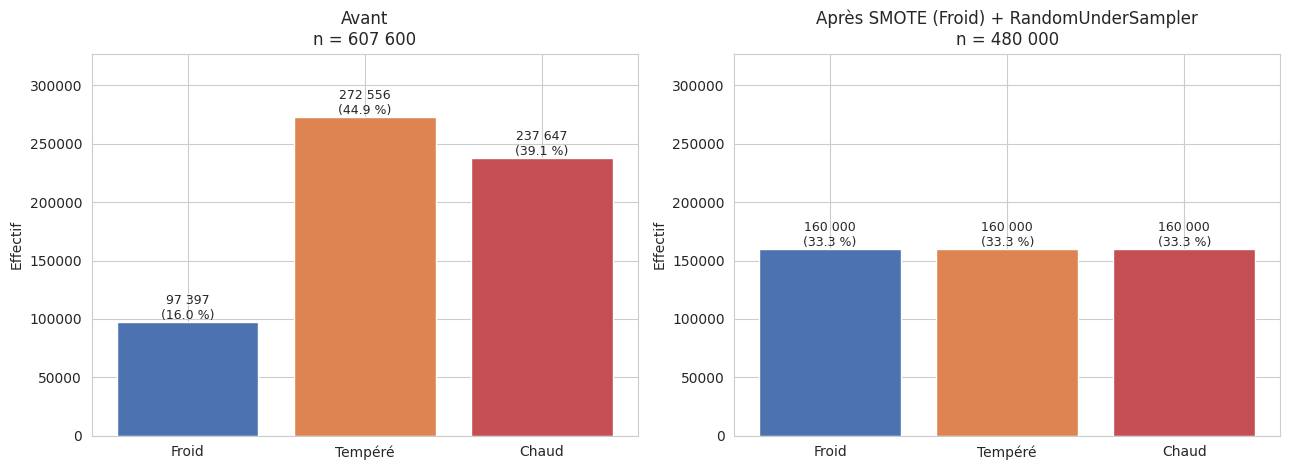

'/content/drive/MyDrive/data mining/resampling/3_combinaison_SMOTE_RUS'

In [8]:
assert n_froid < COMBO_N < min(n_tempere, n_chaud), \
    f"COMBO_N={COMBO_N} doit être compris entre {n_froid} (Froid) et {min(n_tempere, n_chaud)}"

t0 = time.time()
# Étape 1 : SMOTE uniquement sur Froid (classe 0)
smote_c = SMOTE(sampling_strategy={0: COMBO_N}, k_neighbors=5, random_state=SEED)
X_s, y_s = smote_c.fit_resample(X_train, y_train)
X_s, y_s = fix_synthetic(X_s.reset_index(drop=True)), pd.Series(np.asarray(y_s))
print("Après l'étape 1 (SMOTE sur Froid) :", counts(y_s).to_dict())

# Étape 2 : même RandomUnderSampler que le jeu 1, sur Tempéré (1) et Chaud (2)
rus_c = RandomUnderSampler(sampling_strategy={1: COMBO_N, 2: COMBO_N}, random_state=SEED)
X_c, y_c = rus_c.fit_resample(X_s, y_s)
X_c, y_c = X_c.reset_index(drop=True), pd.Series(np.asarray(y_c))
print(f"Combinaison : {fmt(len(X_train))} -> {fmt(len(X_c))} lignes ({time.time() - t0:.1f} s)")

display(pd.concat({"avant": dist_table(y_train), "après": dist_table(y_c)}, axis=1))
d = folder("3_combinaison_SMOTE_RUS")
plot_pair(y_train, y_c, "Avant", "Après SMOTE (Froid) + RandomUnderSampler", path=f"{d}/distribution_avant_apres.png")
save_set("3_combinaison_SMOTE_RUS", X_c, y_c, y_train,
         "SMOTE sur Froid (cible %d) puis RandomUnderSampler sur Tempéré et Chaud (cible %d), random_state=%d" % (COMBO_N, COMBO_N, SEED))

## 3bis. Méthodes ajoutées

Même principe que pour les jeux 1 à 3 : chaque méthode part du train d'origine (`X_train`, `y_train`), le test n'est jamais touché. Les jeux 4 à 11 sont enregistrés dans leur propre dossier et ajoutés à l'entraînement (section 5).

In [ ]:
# Aides pour les jeux ajoutés (4 à 11) : affichage, graphique, sauvegarde et enregistrement dans EXTRA_SETS
EXTRA_SETS, SYNTH = {}, {}

def finish_set(key, X, y, title, note, n_synth=0):
    X, y = X.reset_index(drop=True), pd.Series(np.asarray(y))
    display(pd.concat({"avant": dist_table(y_train), "après": dist_table(y)}, axis=1))
    d = folder(key)
    plot_pair(y_train, y, "Avant", f"Après {title}", path=f"{d}/distribution_avant_apres.png")
    save_set(key, X, y, y_train, note)
    EXTRA_SETS[key] = (X, y)
    SYNTH[key] = int(n_synth)

### 3.4 Jeu 4 : Under-sampling (`NearMiss`, version 1)
Chaque classe est ramenée à l'effectif de Froid en gardant les points dont la distance moyenne aux 3 plus proches voisins de la classe minoritaire est la plus faible. **Peut être long** sur ≈ 800 000 lignes.

In [ ]:
t0 = time.time()
nm = NearMiss(version=1, n_neighbors=3, sampling_strategy="auto", n_jobs=-1)
X_nm, y_nm = nm.fit_resample(X_train, y_train)
print(f"NearMiss : {fmt(len(X_train))} -> {fmt(len(X_nm))} lignes ({time.time() - t0:.1f} s)")
finish_set("4_undersampling_NearMiss", X_nm, y_nm, "NearMiss",
           "NearMiss (version=1, n_neighbors=3, sampling_strategy='auto')")

### 3.5 Jeu 5 : Under-sampling (`TomekLinks`)
Supprime, pour chaque lien de Tomek (deux plus proches voisins mutuels de classes différentes), le point de la classe majoritaire. **Méthode de nettoyage** : les classes ne sont pas équilibrées, seule la frontière est dégagée.

In [ ]:
t0 = time.time()
tl = TomekLinks(sampling_strategy="auto", n_jobs=-1)
X_tl, y_tl = tl.fit_resample(X_train, y_train)
print(f"TomekLinks : {fmt(len(X_train))} -> {fmt(len(X_tl))} lignes ({time.time() - t0:.1f} s)")
finish_set("5_undersampling_Tomek", X_tl, y_tl, "TomekLinks",
           "TomekLinks (sampling_strategy='auto')")

### 3.6 Jeu 6 : Under-sampling (`EditedNearestNeighbours`)
Supprime les points des classes majoritaires dont les 3 plus proches voisins n'appartiennent pas tous à leur classe. Nettoyage plus agressif que Tomek ; les classes ne sont pas parfaitement équilibrées.

In [ ]:
t0 = time.time()
enn = EditedNearestNeighbours(sampling_strategy="auto", n_neighbors=3, kind_sel="all", n_jobs=-1)
X_en, y_en = enn.fit_resample(X_train, y_train)
print(f"ENN : {fmt(len(X_train))} -> {fmt(len(X_en))} lignes ({time.time() - t0:.1f} s)")
finish_set("6_undersampling_ENN", X_en, y_en, "ENN",
           "EditedNearestNeighbours (sampling_strategy='auto', n_neighbors=3, kind_sel='all')")

### 3.7 Jeu 7 : Over-sampling (`RandomOverSampler`)
Froid et Chaud sont complétées par **duplication** de points existants jusqu'à l'effectif de Tempéré. Aucun point synthétique, donc aucune correction `fix_synthetic` nécessaire.

In [ ]:
t0 = time.time()
ros = RandomOverSampler(sampling_strategy="auto", random_state=SEED)
X_r, y_r = ros.fit_resample(X_train, y_train)
print(f"RandomOverSampler : {fmt(len(X_train))} -> {fmt(len(X_r))} lignes ({time.time() - t0:.1f} s)")
finish_set("7_oversampling_ROS", X_r, y_r, "RandomOverSampler",
           "RandomOverSampler (sampling_strategy='auto', random_state=%d) : duplication, pas de points synthétiques" % SEED)

### 3.8 Jeu 8 : Over-sampling (`ADASYN`)
Comme SMOTE, mais le nombre de points synthétiques générés autour d'un point dépend de la difficulté de sa zone (plus de voisins d'autres classes = plus de points). Les effectifs obtenus sont **approximativement** égaux. Correction `fix_synthetic` appliquée.

In [ ]:
t0 = time.time()
ada = ADASYN(sampling_strategy="auto", n_neighbors=5, random_state=SEED, n_jobs=-1)
X_a, y_a = ada.fit_resample(X_train, y_train)
X_a = fix_synthetic(X_a.reset_index(drop=True))
print(f"ADASYN : {fmt(len(X_train))} -> {fmt(len(X_a))} lignes ({time.time() - t0:.1f} s)")
finish_set("8_oversampling_ADASYN", X_a, y_a, "ADASYN",
           "ADASYN (sampling_strategy='auto', n_neighbors=5, random_state=%d), FIX_SYNTHETIC=%s" % (SEED, FIX_SYNTHETIC),
           n_synth=len(X_a) - len(X_train))

### 3.9 Jeu 9 : Over-sampling (`BorderlineSMOTE`)
Seuls les points minoritaires « en danger » (proches de la frontière, selon leurs 10 plus proches voisins) servent de base à l'interpolation. Correction `fix_synthetic` appliquée.

In [ ]:
t0 = time.time()
bsm = BorderlineSMOTE(sampling_strategy="auto", k_neighbors=5, m_neighbors=10, kind="borderline-1", random_state=SEED)
X_b, y_b = bsm.fit_resample(X_train, y_train)
X_b = fix_synthetic(X_b.reset_index(drop=True))
print(f"Borderline-SMOTE : {fmt(len(X_train))} -> {fmt(len(X_b))} lignes ({time.time() - t0:.1f} s)")
finish_set("9_oversampling_BorderlineSMOTE", X_b, y_b, "Borderline-SMOTE",
           "BorderlineSMOTE (kind='borderline-1', k_neighbors=5, m_neighbors=10, random_state=%d), FIX_SYNTHETIC=%s" % (SEED, FIX_SYNTHETIC),
           n_synth=len(X_b) - len(X_train))

### 3.10 Jeu 10 : Combinaison (`SMOTE` + `TomekLinks`)
1. On repart du jeu SMOTE du jeu 2 (`X_o`, `y_o`, déjà corrigé par `fix_synthetic`).
2. `TomekLinks` (`sampling_strategy="all"`, comme `SMOTETomek`) supprime les deux points de chaque lien de Tomek, quelle que soit leur classe.

In [ ]:
t0 = time.time()
tl_c = TomekLinks(sampling_strategy="all", n_jobs=-1)
X_st, y_st = tl_c.fit_resample(X_o, y_o)
n_syn_st = int((tl_c.sample_indices_ >= len(X_train)).sum())   # SMOTE place les points synthétiques après les originaux
print(f"SMOTE + Tomek : {fmt(len(X_o))} -> {fmt(len(X_st))} lignes ({time.time() - t0:.1f} s)")
finish_set("10_combinaison_SMOTE_Tomek", X_st, y_st, "SMOTE + Tomek",
           "SMOTE (jeu 2) puis TomekLinks (sampling_strategy='all'), random_state=%d" % SEED, n_synth=n_syn_st)

### 3.11 Jeu 11 : Combinaison (`SMOTE` + `ENN`)
Même point de départ (jeu SMOTE), puis `EditedNearestNeighbours` (`sampling_strategy="all"`, comme `SMOTEENN`) nettoie toutes les classes : combinaison plus agressive que SMOTE + Tomek.

In [ ]:
t0 = time.time()
enn_c = EditedNearestNeighbours(sampling_strategy="all", n_neighbors=3, kind_sel="all", n_jobs=-1)
X_se, y_se = enn_c.fit_resample(X_o, y_o)
n_syn_se = int((enn_c.sample_indices_ >= len(X_train)).sum())
print(f"SMOTE + ENN : {fmt(len(X_o))} -> {fmt(len(X_se))} lignes ({time.time() - t0:.1f} s)")
finish_set("11_combinaison_SMOTE_ENN", X_se, y_se, "SMOTE + ENN",
           "SMOTE (jeu 2) puis EditedNearestNeighbours (sampling_strategy='all', n_neighbors=3, kind_sel='all')", n_synth=n_syn_se)

## 4. Tableau récapitulatif des distributions (avant + les 11 jeux)

In [ ]:

SETS = {
    "1_undersampling_RUS":     (X_u, y_u),
    "2_oversampling_SMOTE":    (X_o, y_o),
    "3_combinaison_SMOTE_RUS": (X_c, y_c),
}
SETS.update(EXTRA_SETS)                                   # jeux 4 à 11
SYNTH.update({"1_undersampling_RUS": 0, "2_oversampling_SMOTE": len(X_o) - len(X_train),
              "3_combinaison_SMOTE_RUS": COMBO_N - n_froid})

recap = pd.DataFrame({"Avant (train original)": counts(y_train),
                      **{FOLDERS[k]: counts(v[1]) for k, v in SETS.items()}}).T
recap["Total"] = recap.sum(axis=1)
recap_pct = recap[CLASS_NAMES].div(recap["Total"], axis=0).mul(100).round(1)
recap_pct.columns = [f"% {c}" for c in CLASS_NAMES]
recap_all = pd.concat([recap, recap_pct], axis=1)
recap_all["Points synthétiques"] = [0] + [SYNTH[k] for k in SETS]   # RandomOverSampler : 0 (doublons, pas de synthétiques)
display(recap_all)
recap_all.to_csv(f"{OUT_DIR}/recap_distributions.csv")

ax = recap[CLASS_NAMES].plot.bar(figsize=(15, 5.5), color=COLORS, edgecolor="white", rot=30)
ax.set_ylabel("Effectif"); ax.set_title("Répartition des classes : avant et après chaque méthode")
plt.setp(ax.get_xticklabels(), ha="right")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/recap_distributions.png", dpi=130, bbox_inches="tight"); plt.show()


## 5. Entraînement et évaluation de kNN, SVM et Random Forest

Les **mêmes hyperparamètres** sont utilisés sur les trois jeux. Évaluation sur le **test d'origine** (non rééchantillonné).

| Modèle | Hyperparamètres |
|---|---|
| kNN | `n_neighbors=15`, distance euclidienne |
| SVM | `SVC(kernel="rbf", C=1.0, gamma="scale")` |
| Random Forest | `n_estimators=100`, `min_samples_leaf=5` |

**Note sur le SVM.** Un SVM à noyau RBF a un coût au moins quadratique en nombre d'exemples : il est irréalisable sur ≈ 800 000 lignes. Le SVM est donc entraîné sur un sous-échantillon **stratifié** de `SVM_MAX` lignes tiré dans chaque jeu rééchantillonné (la distribution de classes du jeu est conservée). Les deux autres modèles utilisent le jeu complet. Cette limite est à mentionner dans le rapport ; augmentez `SVM_MAX` si votre temps le permet.

**Métriques** : accuracy, balanced accuracy (= rappel macro), précision macro, F1-macro, F1 pondéré, MCC, puis précision / rappel / F1 **par classe**, et les temps d'entraînement et de prédiction.

In [10]:
MODELS = ["kNN", "SVM", "RF"]
LABELS = FOLDERS

def make_models():
    return {
        "kNN": KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
        "SVM": SVC(kernel="rbf", C=1.0, gamma="scale", random_state=SEED),
        "RF":  RandomForestClassifier(n_estimators=100, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    }

def svm_subsample(X, y):
    if len(X) <= SVM_MAX:
        return X, y
    Xs, _, ys, _ = train_test_split(X, y, train_size=SVM_MAX, stratify=y, random_state=SEED)
    return Xs, ys

def evaluate(key, mname, y_pred, n_fit, fit_s, pred_s):
    p, r, f, _ = precision_recall_fscore_support(y_test, y_pred, labels=[0, 1, 2], zero_division=0)
    row = {"jeu": LABELS[key], "modèle": mname, "n_entraînement": n_fit,
           "accuracy":          accuracy_score(y_test, y_pred),
           "balanced_accuracy": balanced_accuracy_score(y_test, y_pred),
           "precision_macro":   p.mean(),
           "F1_macro":          f.mean(),
           "F1_weighted":       f1_score(y_test, y_pred, average="weighted"),
           "MCC":               matthews_corrcoef(y_test, y_pred)}
    for i, c in enumerate(CLASS_NAMES):
        row[f"précision_{c}"], row[f"rappel_{c}"], row[f"F1_{c}"] = p[i], r[i], f[i]
    row["temps_fit_s"], row["temps_pred_s"] = fit_s, pred_s
    return row

results, cms = [], {}

def run_set(key):
    Xs, ys = SETS[key]
    rows = []
    for mname, model in make_models().items():
        Xf, yf = svm_subsample(Xs, ys) if mname == "SVM" else (Xs, ys)
        t0 = time.time(); model.fit(Xf, yf);          fit_s = time.time() - t0
        t0 = time.time(); y_pred = model.predict(X_test); pred_s = time.time() - t0
        row = evaluate(key, mname, y_pred, len(Xf), fit_s, pred_s)
        rows.append(row); results.append(row)
        cms[(LABELS[key], mname)] = confusion_matrix(y_test, y_pred, labels=[0, 1, 2])
        print(f"[{LABELS[key]}] {mname:4s} | n_fit={fmt(len(Xf)):>8} | acc={row['accuracy']:.4f} "
              f"| F1-macro={row['F1_macro']:.4f} | fit {fit_s:6.1f} s | pred {pred_s:6.1f} s")
    pd.DataFrame(rows).to_csv(f"{folder(key)}/resultats_{key}.csv", index=False)   # résultats dans le dossier de la méthode
    return pd.DataFrame(rows)

### 5.1 Jeu 1 : Under-sampling

In [11]:
display(run_set("1_undersampling_RUS").round(4))

[1. Under-sampling (RUS)] kNN  | n_fit= 292 191 | acc=0.8785 | F1-macro=0.8576 | fit    1.8 s | pred   74.9 s
[1. Under-sampling (RUS)] SVM  | n_fit=  50 000 | acc=0.8887 | F1-macro=0.8708 | fit   27.4 s | pred  144.4 s
[1. Under-sampling (RUS)] RF   | n_fit= 292 191 | acc=0.8826 | F1-macro=0.8582 | fit  131.5 s | pred    1.0 s


,jeu,modèle,n_entraînement,accuracy,balanced_accuracy,precision_macro,F1_macro,F1_weighted,MCC,précision_Froid,rappel_Froid,F1_Froid,précision_Tempéré,rappel_Tempéré,F1_Tempéré,précision_Chaud,rappel_Chaud,F1_Chaud,temps_fit_s,temps_pred_s
0,1. Under-sampling (RUS),kNN,292191,0.8785,0.8719,0.8465,0.8576,0.8795,0.8010,0.7421,0.8633,0.7981,0.8528,0.8313,0.8419,0.9446,0.9211,0.9327,1.7559,74.8623
1,1. Under-sampling (RUS),SVM,50000,0.8887,0.8858,0.8593,0.8708,0.8899,0.8181,0.7627,0.8849,0.8192,0.8573,0.8565,0.8569,0.9578,0.9159,0.9364,27.3754,144.3999
2,1. Under-sampling (RUS),RF,292191,0.8826,0.8662,0.8516,0.8582,0.8840,0.8072,0.7541,0.8193,0.7853,0.8397,0.8632,0.8513,0.9610,0.9160,0.9380,131.5245,1.0491


### 5.2 Jeu 2 : Over-sampling (SMOTE)

In [ ]:
display(run_set("2_oversampling_SMOTE").round(4))

[2. Over-sampling (SMOTE)] kNN  | n_fit= 817 668 | acc=0.8760 | F1-macro=0.8544 | fit    6.2 s | pred   98.4 s
[2. Over-sampling (SMOTE)] SVM  | n_fit=  50 000 | acc=0.8970 | F1-macro=0.8844 | fit   25.5 s | pred  136.2 s


### 5.3 Jeu 3 : Combinaison (SMOTE + RUS)

In [ ]:
display(run_set("3_combinaison_SMOTE_RUS").round(4))

### 5.4 Jeu 4 : Under-sampling (NearMiss)

In [ ]:
display(run_set("4_undersampling_NearMiss").round(4))

### 5.5 Jeu 5 : Under-sampling (Tomek Links)

In [ ]:
display(run_set("5_undersampling_Tomek").round(4))

### 5.6 Jeu 6 : Under-sampling (ENN)

In [ ]:
display(run_set("6_undersampling_ENN").round(4))

### 5.7 Jeu 7 : Over-sampling (RandomOverSampler)

In [ ]:
display(run_set("7_oversampling_ROS").round(4))

### 5.8 Jeu 8 : Over-sampling (ADASYN)

In [ ]:
display(run_set("8_oversampling_ADASYN").round(4))

### 5.9 Jeu 9 : Over-sampling (Borderline-SMOTE)

In [ ]:
display(run_set("9_oversampling_BorderlineSMOTE").round(4))

### 5.10 Jeu 10 : Combinaison (SMOTE + Tomek)

In [ ]:
display(run_set("10_combinaison_SMOTE_Tomek").round(4))

### 5.11 Jeu 11 : Combinaison (SMOTE + ENN)

In [ ]:
display(run_set("11_combinaison_SMOTE_ENN").round(4))

## 6. Comparaison finale

In [ ]:
res = pd.DataFrame(results)
SET_ORDER = list(FOLDERS.values())
idx = pd.MultiIndex.from_product([MODELS, SET_ORDER], names=["modèle", "jeu"])

main_cols = ["accuracy", "balanced_accuracy", "precision_macro", "F1_macro", "F1_weighted", "MCC"]
tab_main = res.set_index(["modèle", "jeu"]).reindex(idx)[main_cols].round(4)
print("Métriques globales (test d'origine)"); display(tab_main)

class_cols = [f"{m}_{c}" for c in CLASS_NAMES for m in ("précision", "rappel", "F1")]
tab_class = res.set_index(["modèle", "jeu"]).reindex(idx)[class_cols].round(4)
print("Métriques par classe"); display(tab_class)

tab_cost = res.set_index(["modèle", "jeu"]).reindex(idx)[["n_entraînement", "temps_fit_s", "temps_pred_s"]].round(1)
print("Taille d'entraînement et temps"); display(tab_cost)

best = res.loc[res.groupby("modèle")["F1_macro"].idxmax(), ["modèle", "jeu", "F1_macro"]].set_index("modèle").reindex(MODELS)
print("Meilleur jeu par modèle selon le F1-macro"); display(best.round(4))

res.to_csv(f"{OUT_DIR}/resultats_comparatifs.csv", index=False)
tab_main.to_csv(f"{OUT_DIR}/tableau_metriques_globales.csv")
tab_class.to_csv(f"{OUT_DIR}/tableau_metriques_par_classe.csv")

In [ ]:
# Classement global de toutes les combinaisons (jeu de rééchantillonnage x modèle), pour choisir la meilleure
rank = res.sort_values("F1_macro", ascending=False)[["jeu", "modèle", "F1_macro", "balanced_accuracy", "accuracy", "MCC",
                                                     "rappel_" + CLASS_NAMES[0], "n_entraînement", "temps_fit_s"]].reset_index(drop=True)
rank.index += 1
print("Classement par F1-macro (test d'origine)"); display(rank.round(4))
rank.to_csv(f"{OUT_DIR}/classement_global.csv")

best_overall = rank.iloc[0]
print(f"Meilleure combinaison : {best_overall['jeu']} + {best_overall['modèle']} (F1-macro = {best_overall['F1_macro']:.4f})")

In [ ]:
# Graphiques : métriques globales
fig, axes = plt.subplots(1, 3, figsize=(24, 6.5))
for ax, m in zip(axes, ["accuracy", "balanced_accuracy", "F1_macro"]):
    sns.barplot(data=res, x="modèle", y=m, hue="jeu", order=MODELS, hue_order=SET_ORDER, ax=ax)
    lo, hi = res[m].min(), res[m].max()
    ax.set_ylim(max(0, lo - 0.05), min(1, hi + 0.03))
    ax.set_title(m); ax.legend(fontsize=6, loc="lower right")
    for c in ax.containers:
        ax.bar_label(c, fmt="%.3f", fontsize=5)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/comparaison_metriques_globales.png", dpi=130, bbox_inches="tight"); plt.show()

# Graphiques : rappel par classe (effet sur chaque classe)
fig, axes = plt.subplots(1, 3, figsize=(24, 6.5))
for ax, c in zip(axes, CLASS_NAMES):
    sns.barplot(data=res, x="modèle", y=f"rappel_{c}", hue="jeu", order=MODELS, hue_order=SET_ORDER, ax=ax)
    lo, hi = res[f"rappel_{c}"].min(), res[f"rappel_{c}"].max()
    ax.set_ylim(max(0, lo - 0.05), min(1, hi + 0.03))
    ax.set_title(f"Rappel : {c}"); ax.legend(fontsize=6, loc="lower right")
    for cc in ax.containers:
        ax.bar_label(cc, fmt="%.3f", fontsize=5)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/comparaison_rappel_par_classe.png", dpi=130, bbox_inches="tight"); plt.show()

In [ ]:

# Matrices de confusion (normalisées par ligne : chaque case = part des vraies observations de la classe)
# Disposition : une ligne par jeu de rééchantillonnage, une colonne par modèle (11 jeux x 3 modèles)
fig, axes = plt.subplots(len(SET_ORDER), len(MODELS), figsize=(4.6 * len(MODELS), 3.9 * len(SET_ORDER)))
for i, s in enumerate(SET_ORDER):
    for j, m in enumerate(MODELS):
        cm = cms[(s, m)]
        cmn = cm / cm.sum(axis=1, keepdims=True)
        sns.heatmap(cmn, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                    xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=axes[i, j])
        axes[i, j].set_title(f"{m} | {s}", fontsize=9)
        axes[i, j].set_xlabel("Prédit"); axes[i, j].set_ylabel("Réel")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/matrices_confusion.png", dpi=110, bbox_inches="tight"); plt.show()


## 7. Sauvegardes et points à commenter dans le rapport

Arborescence créée dans `OUT_DIR` :

```
resampling/
├── 1_undersampling_RUS/        train rééchantillonné, distribution (csv + png), résultats, README
├── 2_oversampling_SMOTE/       idem
├── 3_combinaison_SMOTE_RUS/    idem
├── 4_ ... 11_ (NearMiss, Tomek, ENN, RandomOver, ADASYN, Borderline-SMOTE, SMOTE+Tomek, SMOTE+ENN)   idem
├── recap_distributions.csv / .png
├── resultats_comparatifs.csv, tableau_metriques_globales.csv, tableau_metriques_par_classe.csv, classement_global.csv
└── comparaison_*.png, matrices_confusion.png
```

**À discuter dans le rapport**
- Effet de chaque méthode sur le **rappel de la classe Froid** (la minoritaire) comparé à l'accuracy : un rééchantillonnage peut améliorer l'un en dégradant l'autre.
- Accuracy et F1-macro ne bougent pas forcément dans le même sens : le test garde la distribution d'origine (et 2026 est une année incomplète).
- Under-sampling : information perdue, jeu plus petit, entraînement plus rapide. Over-sampling : points synthétiques, jeu plus grand, entraînement plus lent. Combinaison : compromis.
- Sensibilité des modèles : kNN et SVM (distances, points synthétiques) contre Random Forest.
- Limites : SVM entraîné sur un sous-échantillon stratifié ; SMOTE interpole aussi `month` et `year` (corrigés ensuite si `FIX_SYNTHETIC = True`) ; hyperparamètres identiques et non réglés.- Méthodes de nettoyage (Tomek, ENN) : elles n'équilibrent pas les classes, elles dégagent la frontière ; comparer leur effet à celui des méthodes qui équilibrent.
- NearMiss : garde les points proches de la classe minoritaire, ce qui peut déformer la distribution de la classe majoritaire.
- RandomOverSampler : doublons exacts, risque de surapprentissage (surtout pour kNN et Random Forest).
- ADASYN / Borderline-SMOTE : synthétiques concentrés près de la frontière ; effectifs ADASYN seulement approximativement égaux.
- SMOTE + Tomek / SMOTE + ENN : le nettoyage retire aussi des points synthétiques (voir la colonne « Points synthétiques » du récapitulatif).
- Choix final : s'appuyer sur le classement global (`classement_global.csv`), en regardant le F1-macro mais aussi le rappel de Froid et le MCC.
